# Rakathon 2026: exploratory data analysis

**Dataset:** `data/Rakhaton2026.csv`. Each row is one addressed invitation to **mammography screening**, sent by VZP (2020–2024).
**Task:** predict whether the invited woman attends screening within 3, 6 or 12 months of the invitation date (T0).

Column semantics come from `data/Rakathon_Datove_rozhrani.docx`. Boolean columns use Czech flags: `A` = *ano* (yes), `N` = *ne* (no).

| Group | Columns |
|---|---|
| Keys | `INVITATION_ID`, `PERSON_ID`, `INVITATION_DATE` (T0) |
| Invitation history | `PRIOR_INVITATION_COUNT`, `INVITATION_SEQUENCE`, `MONTHS_LAST_INVITATION`, `FIRST_INVITATION` |
| Demography / region | `AGE_BAND`, `VZP_TERRITORIAL_AREA` (VZP branch, **not** an administrative district) |
| Insurance & registration | `INSURANCE_DURATION_YEARS`, `GP_REGISTERED`, `GP_REG_DURATION_BAND`, `GYN_REGISTERED_FLAG`, `GYN_REG_DURATION_BAND` |
| Screening history (B3) | `PRIOR_SCREEN_COUNT_5Y`, `MONTHS_SINCE_LAST_SCREEN`, `NEVER_SCREENED_BEFORE_FLAG` |
| Preventive behaviour (B4) | `HEALTHCARE_CONTACT_12M_CNT`, `GP_PREVENTION_24M_CNT`, `GYN_PREVENTION_24M_CNT`, `OTHER_SCREENING_36M_CNT`, `DENTAL_PREVENTION_24M_CNT` |
| Labels | `SCREENING_3M_FLAG`, `SCREENING_6M_FLAG`, `SCREENING_12M_FLAG` |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA = Path("../data/Rakhaton2026.csv")

# Validated categorical palette (fixed order) + neutral ink colours
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.prop_cycle": plt.cycler(color=[C1, C2, C3]),
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
pct = mtick.PercentFormatter(1.0, decimals=None)

## 1. Load and schema

In [2]:
FLAG_COLS = ["FIRST_INVITATION", "GP_REGISTERED", "GYN_REGISTERED_FLAG", "NEVER_SCREENED_BEFORE_FLAG",
             "SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]

raw = pd.read_csv(DATA, dtype={"PERSON_ID": str, "INVITATION_ID": str},
                  keep_default_na=False, na_values=[""])
df = raw.copy()
df["INVITATION_DATE"] = pd.to_datetime(df["INVITATION_DATE"], format="%d.%m.%Y")
for c in FLAG_COLS:
    assert set(df[c].unique()) <= {"A", "N"}, c
    df[c] = df[c].eq("A")
for c in ["AGE_BAND", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]:
    df[c] = df[c].astype("category")
df["VZP_TERRITORIAL_AREA"] = df["VZP_TERRITORIAL_AREA"].astype("category")

print(f"{len(df):,} invitations | {df.PERSON_ID.nunique():,} women | {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.head()

1,344,556 invitations | 508,527 women | 25 columns
Memory: 320 MB


,INVITATION_ID,PERSON_ID,INVITATION_DATE,AGE_BAND,VZP_TERRITORIAL_AREA,PRIOR_INVITATION_COUNT,MONTHS_LAST_INVITATION,INVITATION_SEQUENCE,HEALTHCARE_CONTACT_12M_CNT,FIRST_INVITATION,INSURANCE_DURATION_YEARS,GP_REGISTERED,GP_REG_DURATION_BAND,GYN_REGISTERED_FLAG,GYN_REG_DURATION_BAND,PRIOR_SCREEN_COUNT_5Y,MONTHS_SINCE_LAST_SCREEN,NEVER_SCREENED_BEFORE_FLAG,GP_PREVENTION_24M_CNT,GYN_PREVENTION_24M_CNT,OTHER_SCREENING_36M_CNT,DENTAL_PREVENTION_24M_CNT,SCREENING_3M_FLAG,SCREENING_6M_FLAG,SCREENING_12M_FLAG
0,INV000000000000270,923546909213458,2020-01-14,70-74,JIČÍN,7,12.0,7,7,False,28,True,>5,False,NaN,0,NaN,True,0,0,0,0,False,False,False
1,INV000000000000273,439672095098918,2020-01-14,70-74,PÍSEK,4,12.0,4,10,False,28,True,>5,True,>5,0,NaN,True,0,0,0,2,False,False,False
2,INV000000000000276,150998219588515,2020-01-14,70-74,STRAKONICE,7,12.0,7,7,False,28,True,>5,True,>5,0,NaN,True,1,0,1,1,True,True,True
3,INV000000000000283,402004958199037,2020-01-14,70-74,LIBEREC,6,12.0,6,20,False,9,True,>5,True,2-5,0,NaN,True,0,1,0,2,False,False,False
4,INV000000000000288,371784222157673,2020-01-14,70-74,PRAHA-HL.MĚSTO,7,12.0,7,0,False,28,True,>5,False,NaN,0,NaN,True,0,0,0,0,False,False,False


In [3]:
df.dtypes.to_frame('dtype').T

,INVITATION_ID,PERSON_ID,INVITATION_DATE,AGE_BAND,VZP_TERRITORIAL_AREA,PRIOR_INVITATION_COUNT,MONTHS_LAST_INVITATION,INVITATION_SEQUENCE,HEALTHCARE_CONTACT_12M_CNT,FIRST_INVITATION,INSURANCE_DURATION_YEARS,GP_REGISTERED,GP_REG_DURATION_BAND,GYN_REGISTERED_FLAG,GYN_REG_DURATION_BAND,PRIOR_SCREEN_COUNT_5Y,MONTHS_SINCE_LAST_SCREEN,NEVER_SCREENED_BEFORE_FLAG,GP_PREVENTION_24M_CNT,GYN_PREVENTION_24M_CNT,OTHER_SCREENING_36M_CNT,DENTAL_PREVENTION_24M_CNT,SCREENING_3M_FLAG,SCREENING_6M_FLAG,SCREENING_12M_FLAG
dtype,object,object,datetime64[ns],category,category,int64,float64,int64,int64,bool,int64,bool,category,bool,category,int64,float64,bool,int64,int64,int64,int64,bool,bool,bool


In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
INVITATION_DATE,1344556,2022-06-28 03:07:25.669202688,2020-01-14 00:00:00,2021-04-09 00:00:00,2022-06-15 00:00:00,2023-09-13 00:00:00,2024-12-06 00:00:00,NaN
PRIOR_INVITATION_COUNT,1344556.0,5.093778,1.0,2.0,5.0,8.0,11.0,3.102906
MONTHS_LAST_INVITATION,1115329.0,15.242588,8.0,11.0,12.0,12.0,120.0,13.513922
INVITATION_SEQUENCE,1344556.0,4.827278,1.0,2.0,4.0,8.0,11.0,3.204227
HEALTHCARE_CONTACT_12M_CNT,1344556.0,15.947105,0.0,5.0,12.0,22.0,450.0,16.211469
INSURANCE_DURATION_YEARS,1344556.0,27.055716,5.0,26.0,29.0,31.0,32.0,5.665121
PRIOR_SCREEN_COUNT_5Y,1344556.0,0.393915,0.0,0.0,0.0,0.0,18.0,0.888477
MONTHS_SINCE_LAST_SCREEN,244270.0,39.276055,0.0,37.0,43.0,50.0,76.0,17.55009
GP_PREVENTION_24M_CNT,1344556.0,0.445579,0.0,0.0,0.0,1.0,9.0,0.564932
GYN_PREVENTION_24M_CNT,1344556.0,0.551119,0.0,0.0,0.0,1.0,9.0,0.812454


## 2. Data quality

### 2.1 Missingness is structural, not random
Every column with NaNs maps to a flag that explains why the value is missing.

In [5]:
na = df.isna().sum()
na = na[na > 0].to_frame("n_missing").assign(share=lambda t: t.n_missing / len(df))
na

,n_missing,share
MONTHS_LAST_INVITATION,229227,0.170485
GP_REG_DURATION_BAND,19370,0.014406
GYN_REG_DURATION_BAND,288783,0.214779
MONTHS_SINCE_LAST_SCREEN,1100286,0.818327


In [6]:
checks = {
    "MONTHS_LAST_INVITATION NaN  <=> FIRST_INVITATION": (df.MONTHS_LAST_INVITATION.isna() == df.FIRST_INVITATION).all(),
    "MONTHS_SINCE_LAST_SCREEN NaN <=> NEVER_SCREENED_BEFORE": (df.MONTHS_SINCE_LAST_SCREEN.isna() == df.NEVER_SCREENED_BEFORE_FLAG).all(),
    "NEVER_SCREENED <=> PRIOR_SCREEN_COUNT_5Y == 0": (df.NEVER_SCREENED_BEFORE_FLAG == df.PRIOR_SCREEN_COUNT_5Y.eq(0)).all(),
    "GP_REG_DURATION_BAND NaN <=> not GP_REGISTERED": (df.GP_REG_DURATION_BAND.isna() == ~df.GP_REGISTERED).all(),
    "GYN_REG_DURATION_BAND NaN <=> not GYN_REGISTERED": (df.GYN_REG_DURATION_BAND.isna() == ~df.GYN_REGISTERED_FLAG).all(),
    "labels nested: 3M => 6M => 12M": ((~df.SCREENING_3M_FLAG | df.SCREENING_6M_FLAG) & (~df.SCREENING_6M_FLAG | df.SCREENING_12M_FLAG)).all(),
    "INVITATION_ID unique": df.INVITATION_ID.is_unique,
    "no fully duplicated rows": not raw.drop(columns="INVITATION_ID").duplicated().any(),
}
pd.Series(checks, name="holds").to_frame()

,holds
MONTHS_LAST_INVITATION NaN <=> FIRST_INVITATION,True
MONTHS_SINCE_LAST_SCREEN NaN <=> NEVER_SCREENED_BEFORE,True
NEVER_SCREENED <=> PRIOR_SCREEN_COUNT_5Y == 0,False
GP_REG_DURATION_BAND NaN <=> not GP_REGISTERED,True
GYN_REG_DURATION_BAND NaN <=> not GYN_REGISTERED,True
labels nested: 3M => 6M => 12M,True
INVITATION_ID unique,True
no fully duplicated rows,True


**Note.** "Never screened before" really means *no screening in the 60-month look-back window*. It does not mean never screened in her lifetime.
The check below looks at the oddities in the screening-history columns.

In [7]:
mls = df.MONTHS_SINCE_LAST_SCREEN
print("MONTHS_SINCE_LAST_SCREEN > 60 (outside documented 5y window):", (mls > 60).sum())
print("MONTHS_SINCE_LAST_SCREEN == 0 (screened in the month of T0):", (mls == 0).sum())
edge = df[~df.NEVER_SCREENED_BEFORE_FLAG & df.PRIOR_SCREEN_COUNT_5Y.eq(0)]
print(f"NEVER_SCREENED = N but PRIOR_SCREEN_COUNT_5Y = 0: {len(edge):,} rows, MONTHS_SINCE_LAST_SCREEN in "
      f"[{edge.MONTHS_SINCE_LAST_SCREEN.min():.0f}, {edge.MONTHS_SINCE_LAST_SCREEN.max():.0f}]  -> 60-month window edge effect")
print("PRIOR_INVITATION_COUNT == INVITATION_SEQUENCE:", f"{(df.PRIOR_INVITATION_COUNT == df.INVITATION_SEQUENCE).mean():.1%}")
print("PRIOR_INVITATION_COUNT <  INVITATION_SEQUENCE:", (df.PRIOR_INVITATION_COUNT < df.INVITATION_SEQUENCE).sum())
display(pd.crosstab(df.FIRST_INVITATION, df.INVITATION_SEQUENCE, margins=True))
print("PRIOR_SCREEN_COUNT_5Y distribution (note: 2 dominates, so it likely counts claim codes, not visits):")
df.PRIOR_SCREEN_COUNT_5Y.value_counts().sort_index().head(10).to_frame("rows").T

MONTHS_SINCE_LAST_SCREEN > 60 (outside documented 5y window): 193
MONTHS_SINCE_LAST_SCREEN == 0 (screened in the month of T0): 23677
NEVER_SCREENED = N but PRIOR_SCREEN_COUNT_5Y = 0: 3,354 rows, MONTHS_SINCE_LAST_SCREEN in [60, 76]  -> 60-month window edge effect
PRIOR_INVITATION_COUNT == INVITATION_SEQUENCE: 88.0%
PRIOR_INVITATION_COUNT <  INVITATION_SEQUENCE: 0


INVITATION_SEQUENCE,1,2,3,4,5,6,7,8,9,10,11,All
FIRST_INVITATION,,,,,,,,,,,,
False,59977,170395,126631,104845,93913,75868,142987,117981,93420,71515,57797,1115329
True,229175,52,0,0,0,0,0,0,0,0,0,229227
All,289152,170447,126631,104845,93913,75868,142987,117981,93420,71515,57797,1344556


PRIOR_SCREEN_COUNT_5Y distribution (note: 2 dominates, so it likely counts claim codes, not visits):


PRIOR_SCREEN_COUNT_5Y,0,1,2,3,4,5,6,7,8,9
rows,1103640,8103,196238,20950,13189,1650,591,82,40,21


## 3. Targets

,cumulative rate,incremental share,positives
SCREENING_3M_FLAG,0.071227,0.071227,95769
SCREENING_6M_FLAG,0.125410,0.054183,168621
SCREENING_12M_FLAG,0.193027,0.067617,259536


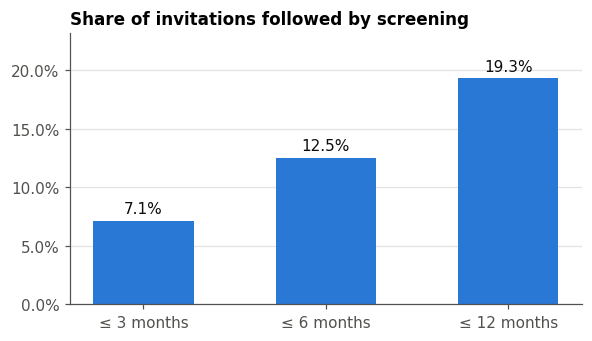

In [8]:
rates = df[LABELS].mean()
incr = rates.diff().fillna(rates)
display(pd.DataFrame({"cumulative rate": rates, "incremental share": incr, "positives": df[LABELS].sum()}))

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(["≤ 3 months", "≤ 6 months", "≤ 12 months"], rates.values, width=0.55, color=C1)
ax.bar_label(bars, labels=[f"{r:.1%}" for r in rates], padding=3, color=INK)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, rates.max() * 1.2)
ax.set_title("Share of invitations followed by screening")
plt.show()

Labels are nested and imbalanced. Only **~19%** of invitations lead to screening within a year, and **~37%** of those who respond do so only after 6 months.

## 4. Time dimension

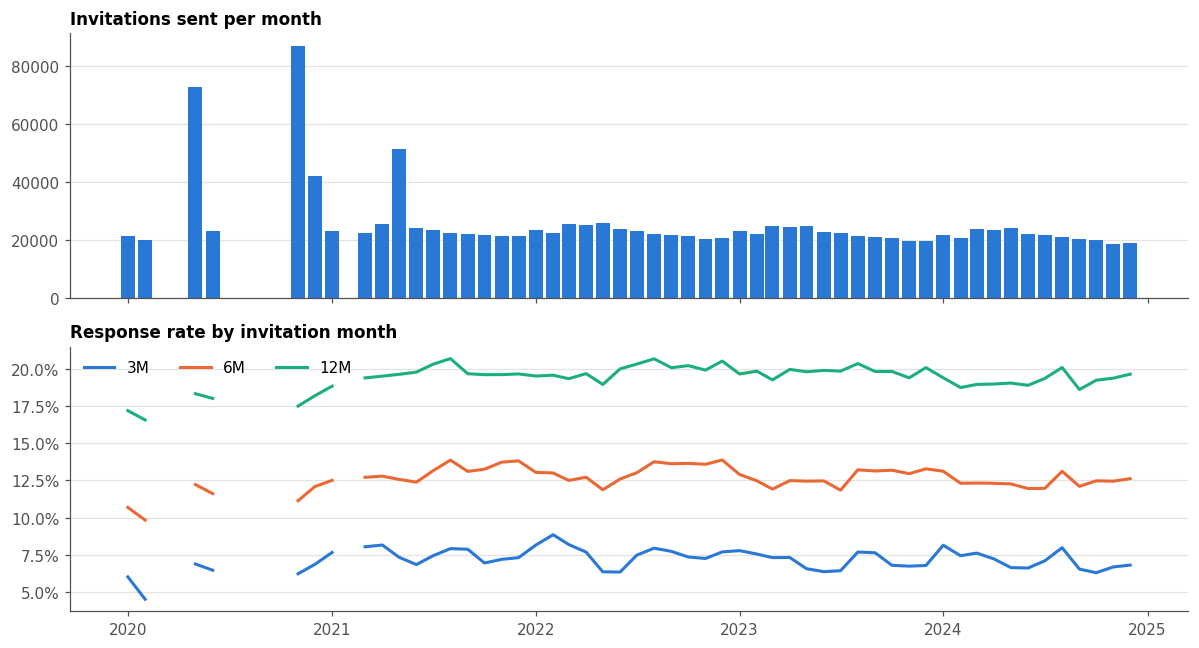

In [9]:
m = df.set_index("INVITATION_DATE").resample("MS")
monthly = pd.DataFrame({"invitations": m.size(), **{l: m[l].mean() for l in LABELS}})

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
a1.bar(monthly.index, monthly.invitations, width=25, color=C1)
a1.set_title("Invitations sent per month")
for l, c in zip(LABELS, [C1, C2, C3]):
    a2.plot(monthly.index, monthly[l], color=c, label=l.split("_")[1])
a2.yaxis.set_major_formatter(pct); a2.set_title("Response rate by invitation month")
a2.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

In [10]:
by_year = df.groupby(df.INVITATION_DATE.dt.year)[LABELS].mean()
by_year.insert(0, "n", df.groupby(df.INVITATION_DATE.dt.year).size())
by_year.style.format({l: "{:.1%}" for l in LABELS} | {"n": "{:,}"})

,n,SCREENING_3M_FLAG,SCREENING_6M_FLAG,SCREENING_12M_FLAG
INVITATION_DATE,,,,
2020,"266,502",6.4%,11.5%,17.8%
2021,"279,010",7.5%,13.0%,19.7%
2022,"275,993",7.6%,13.1%,19.9%
2023,"266,585",7.1%,12.7%,19.8%
2024,"256,466",7.1%,12.4%,19.2%


In [11]:
dow = df.INVITATION_DATE.dt.day_name().value_counts()
print("Invitation weekday distribution:"); print(dow)
print("Distinct invitation dates:", df.INVITATION_DATE.nunique())
print()
print("First-invitation share by age band:")
df.groupby("AGE_BAND", observed=True).FIRST_INVITATION.mean().map("{:.1%}".format).to_frame().T

Invitation weekday distribution:
INVITATION_DATE
Thursday     314609
Tuesday      314561
Wednesday    267100
Friday       242837
Monday       159467
Saturday      23583
Sunday        22399
Name: count, dtype: int64
Distinct invitation dates: 60

First-invitation share by age band:


AGE_BAND,40-44,45-49,50-54,55-59,60-64,65-69,70-74
FIRST_INVITATION,100.0%,33.5%,3.1%,6.4%,6.3%,6.2%,6.5%


Invitations go out in batches on a limited set of dates. The response rate shows clear dips: 2020 is visibly lower (COVID).
The 12-month labels for invitations sent in late 2024 depend on claims up to late 2025. The data doc says insurance was tracked until 31.12.2025, so the windows should be complete, but this is worth confirming with the organisers.

## 5. Women with repeated invitations

In [12]:
per_person = df.groupby("PERSON_ID", observed=True)
n_rows = per_person.size()
display(n_rows.value_counts().sort_index().to_frame("women").assign(share=lambda t: t.women / t.women.sum()))
print(f"Rows belonging to women with >1 invitation: {(n_rows[n_rows > 1].sum() / len(df)):.1%}")

,women,share
1,190970,0.375536
2,95778,0.188344
3,54097,0.106380
4,38671,0.076045
5,129011,0.253695


Rows belonging to women with >1 invitation: 85.8%


In [13]:
# Order each woman's invitations and look at consecutive pairs
s = df.sort_values(["PERSON_ID", "INVITATION_DATE"])
g = s.groupby("PERSON_ID", observed=True)
s["prev_date"] = g.INVITATION_DATE.shift()
s["prev_12m"] = g.SCREENING_12M_FLAG.shift()
s["prev_seq"] = g.INVITATION_SEQUENCE.shift()
s["prev_prior_screen"] = g.PRIOR_SCREEN_COUNT_5Y.shift()
pairs = s.dropna(subset=["prev_date"]).copy()
pairs["gap_months"] = (pairs.INVITATION_DATE - pairs.prev_date).dt.days / 30.44

print("Gap between consecutive invitations in dataset (months):")
display(pairs.gap_months.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame().T)
print(f"Consecutive invitations < 12 months apart (overlapping 12M label windows): {(pairs.gap_months < 12).mean():.1%}")
print(f"PRIOR_INVITATION_COUNT constant within woman: {(per_person.PRIOR_INVITATION_COUNT.nunique() == 1).mean():.1%}")
print(f"INVITATION_SEQUENCE increases by exactly 1: {(pairs.INVITATION_SEQUENCE - pairs.prev_seq).eq(1).mean():.1%}")

Gap between consecutive invitations in dataset (months):


,count,mean,std,min,5%,25%,50%,75%,95%,max
gap_months,836029.0,12.21438,3.986698,8.409987,9.78975,11.695138,11.925099,12.122208,12.516426,48.554534


Consecutive invitations < 12 months apart (overlapping 12M label windows): 66.6%
PRIOR_INVITATION_COUNT constant within woman: 37.6%
INVITATION_SEQUENCE increases by exactly 1: 99.2%


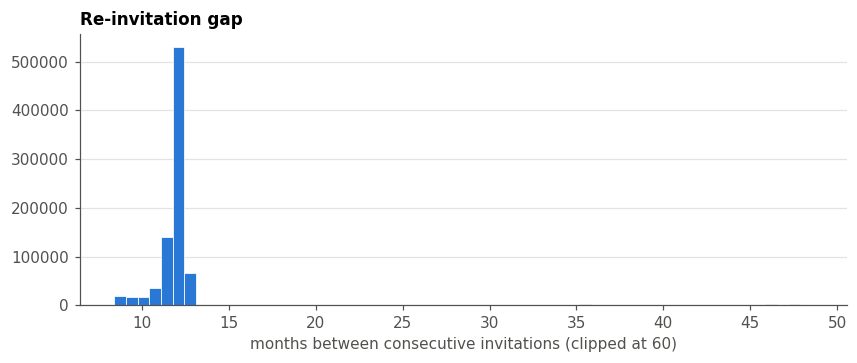

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(pairs.gap_months.clip(upper=60), bins=60, color=C1, edgecolor="white", linewidth=0.5)
ax.set_xlabel("months between consecutive invitations (clipped at 60)"); ax.set_title("Re-invitation gap")
plt.show()

**Consistency check.** If a woman responded to invitation *k*, her screening history at invitation *k+1* should reflect it. A large mismatch would point to a feature-construction problem.

In [15]:
inc = pairs.PRIOR_SCREEN_COUNT_5Y - pairs.prev_prior_screen
pd.crosstab(pairs.prev_12m.astype(bool).map({True: "prev screened ≤12M", False: "prev not screened"}),
            np.sign(inc).map({-1: "count fell", 0: "count same", 1: "count rose"}), normalize="index").style.format("{:.1%}")

col_0,count fell,count rose,count same
prev_12m,,,
prev not screened,5.7%,0.1%,94.2%
prev screened ≤12M,2.4%,74.3%,23.2%


In [16]:
habit = pairs.groupby(pairs.prev_12m.astype(bool))[LABELS].mean()
habit.index = habit.index.map({True: "screened after previous invitation", False: "did not screen after previous"})
habit.style.format("{:.1%}")

,SCREENING_3M_FLAG,SCREENING_6M_FLAG,SCREENING_12M_FLAG
prev_12m,,,
did not screen after previous,3.4%,6.6%,11.3%
screened after previous invitation,16.2%,19.8%,23.4%


Previous behaviour carries most of the signal. Because the same woman appears up to 5 times, **train/validation splits must be grouped by `PERSON_ID`**, or done out-of-time, to avoid leakage.

## 6. Response rate by feature

In [17]:
BASE = df.SCREENING_12M_FLAG.mean()

def rate_plot(col, data=df, ax=None, order=None, min_n=500, title=None, rot=0):
    t = data.groupby(col, observed=True, dropna=False).SCREENING_12M_FLAG.agg(["mean", "size"])
    t = t[t["size"] >= min_n]
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    ax = ax or plt.subplots(figsize=(8, 3))[1]
    x = [str(i) for i in t.index]
    ax.bar(x, t["mean"], width=0.65, color=C1)
    ax.axhline(BASE, color=INK2, lw=1, ls="--")
    ax.yaxis.set_major_formatter(pct)
    ax.set_title(title or col)
    ax.tick_params(axis="x", rotation=rot)
    ax2 = ax.twiny(); ax2.set_xlim(ax.get_xlim()); ax2.set_xticks(range(len(x)))
    ax2.set_xticklabels([f"{n/1000:.0f}k" if n >= 1000 else str(n) for n in t["size"]], fontsize=7, color=INK2)
    ax2.tick_params(length=0); ax2.grid(False); [s.set_visible(False) for s in ax2.spines.values()]
    return t

print(f"Dashed line = overall 12M response rate ({BASE:.1%}); top axis = number of invitations in the bin")

Dashed line = overall 12M response rate (19.3%); top axis = number of invitations in the bin


### 6.1 Demography

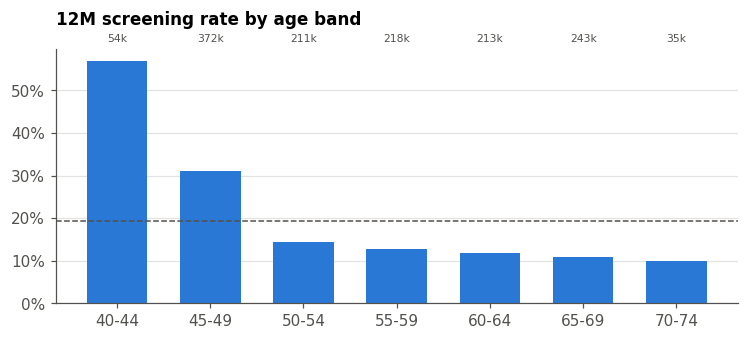

,mean,size
AGE_BAND,,
40-44,56.8%,"53,616"
45-49,31.1%,"371,835"
50-54,14.4%,"211,093"
55-59,12.8%,"217,696"
60-64,11.9%,"212,906"
65-69,11.0%,"242,690"
70-74,10.0%,"34,720"


In [18]:
t = rate_plot("AGE_BAND", title="12M screening rate by age band")
plt.show(); t.style.format({"mean": "{:.1%}", "size": "{:,}"})

**The 40–44 band responds at ~57%.** The Czech programme starts at 45 and invitations go out in the birthday month, so this band is probably women aged 44 being invited just before eligibility.
It could also be self-referred or diagnostic cases. Either way, it is a very different population and may be worth modelling separately. The 45–49 band (the first regular invitations) is also high.

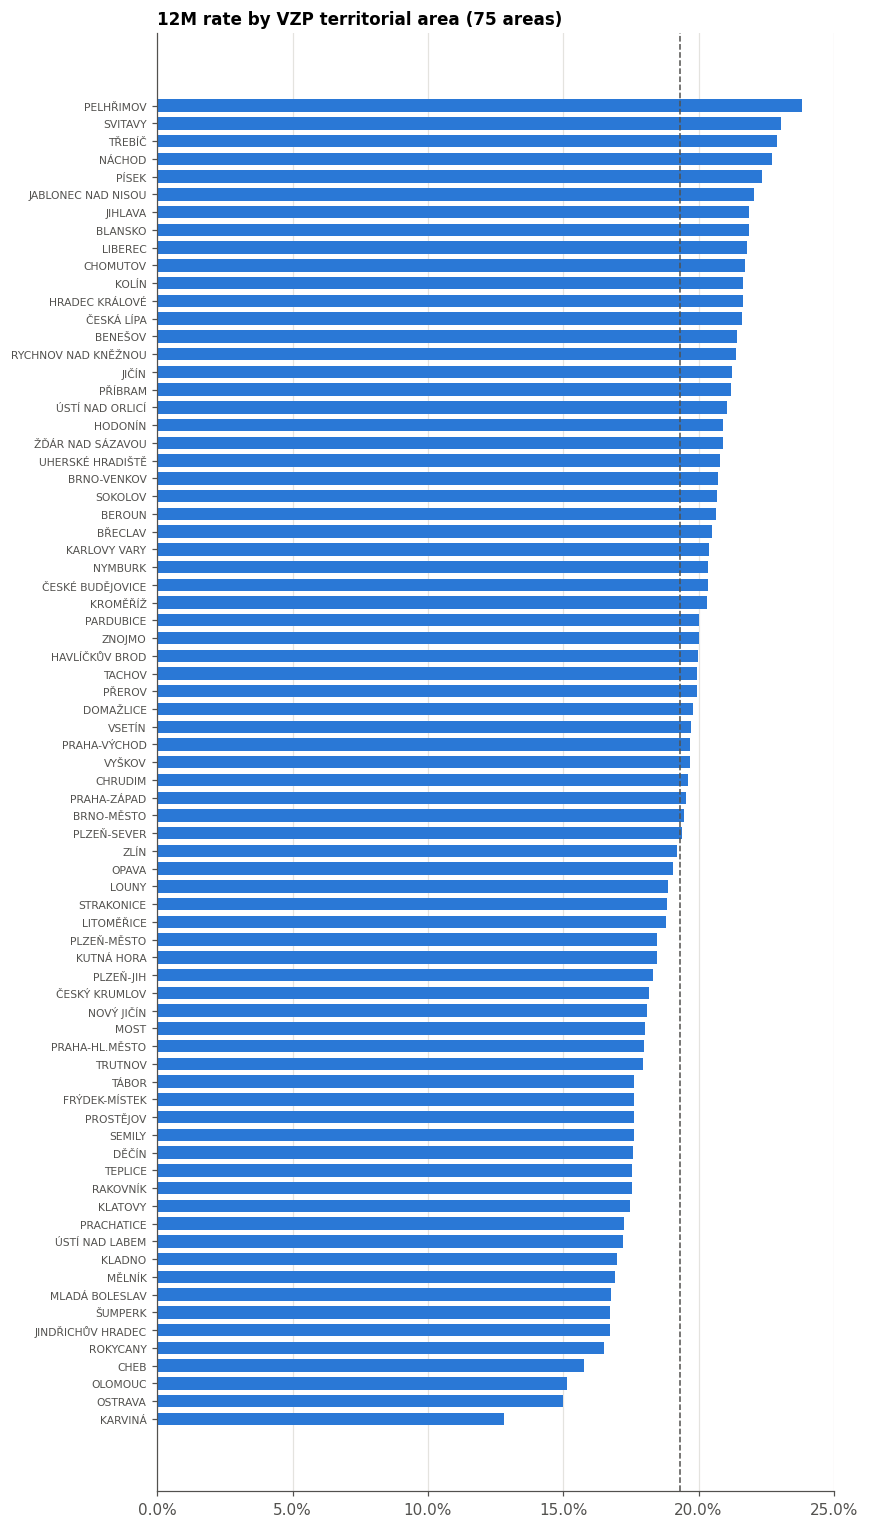

Range: 12.8% – 23.8%;  size range 5,089 – 193,569


In [19]:
area = df.groupby("VZP_TERRITORIAL_AREA", observed=True).SCREENING_12M_FLAG.agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(area.index.astype(str), area["mean"], height=0.7, color=C1)
ax.axvline(BASE, color=INK2, lw=1, ls="--")
ax.xaxis.set_major_formatter(pct); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7); ax.set_title(f"12M rate by VZP territorial area ({len(area)} areas)")
plt.tight_layout(); plt.show()
print(f"Range: {area['mean'].min():.1%} – {area['mean'].max():.1%};  size range {area['size'].min():,} – {area['size'].max():,}")

### 6.2 Invitation history

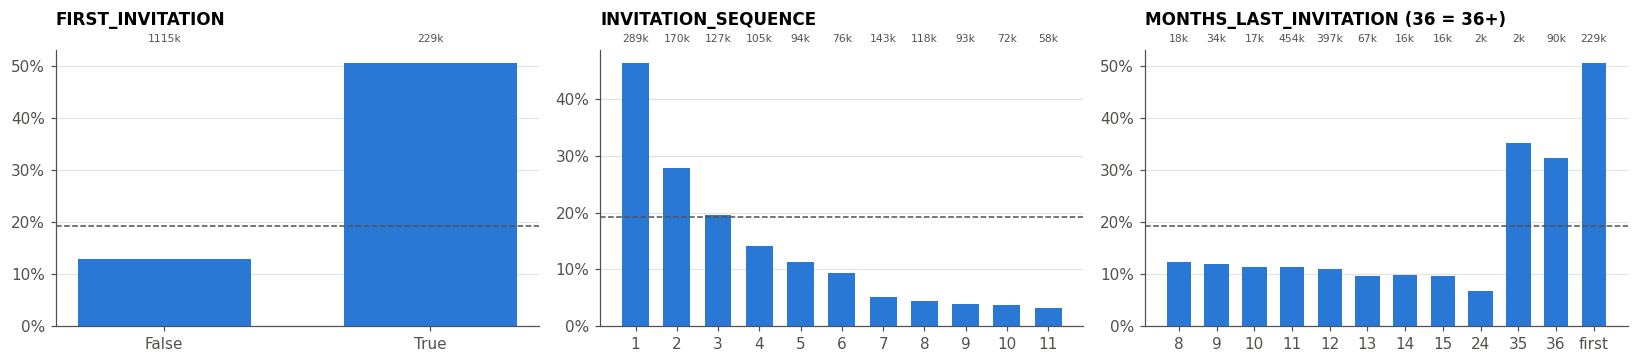

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
rate_plot("FIRST_INVITATION", ax=axes[0])
rate_plot("INVITATION_SEQUENCE", ax=axes[1])
d = df.assign(MLI=df.MONTHS_LAST_INVITATION.clip(upper=36).astype("Int64").astype(str).replace("<NA>", "first"))
order = [str(i) for i in range(8, 37)] + ["first"]
rate_plot("MLI", data=d, ax=axes[2], order=order, title="MONTHS_LAST_INVITATION (36 = 36+)")
plt.tight_layout(); plt.show()

### 6.3 Screening history: the strongest group

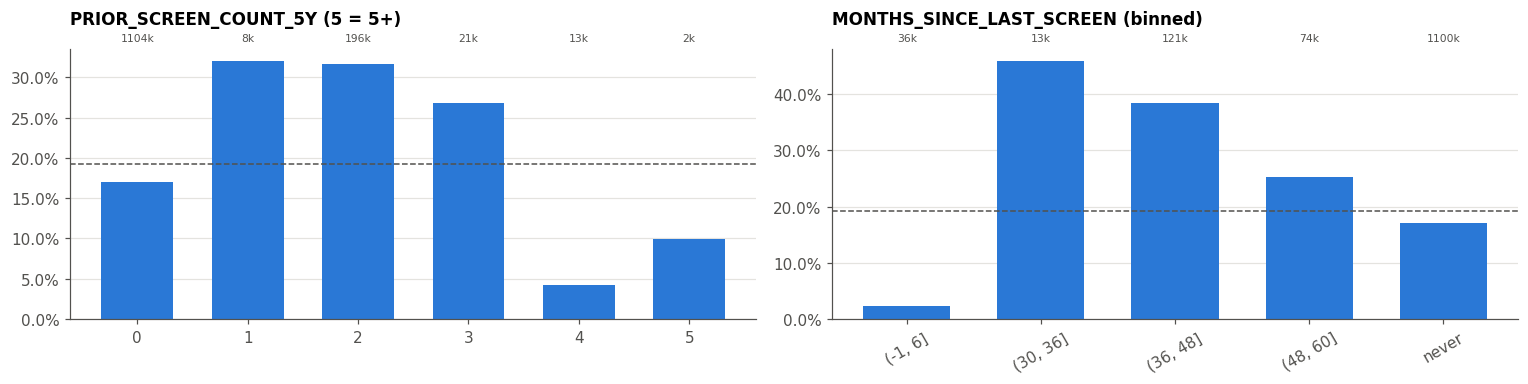

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
d = df.assign(PSC=df.PRIOR_SCREEN_COUNT_5Y.clip(upper=5))
rate_plot("PSC", data=d, ax=axes[0], title="PRIOR_SCREEN_COUNT_5Y (5 = 5+)")
d = df.assign(MSLS=pd.cut(df.MONTHS_SINCE_LAST_SCREEN, bins=[-1, 6, 12, 18, 21, 24, 27, 30, 36, 48, 60, 80]).astype(str)
              .where(df.MONTHS_SINCE_LAST_SCREEN.notna(), "never"))
order = [str(i) for i in pd.cut(pd.Series([0]), bins=[-1, 6, 12, 18, 21, 24, 27, 30, 36, 48, 60, 80]).cat.categories] + ["never"]
rate_plot("MSLS", data=d, ax=axes[1], order=order, title="MONTHS_SINCE_LAST_SCREEN (binned)", rot=30)
plt.tight_layout(); plt.show()

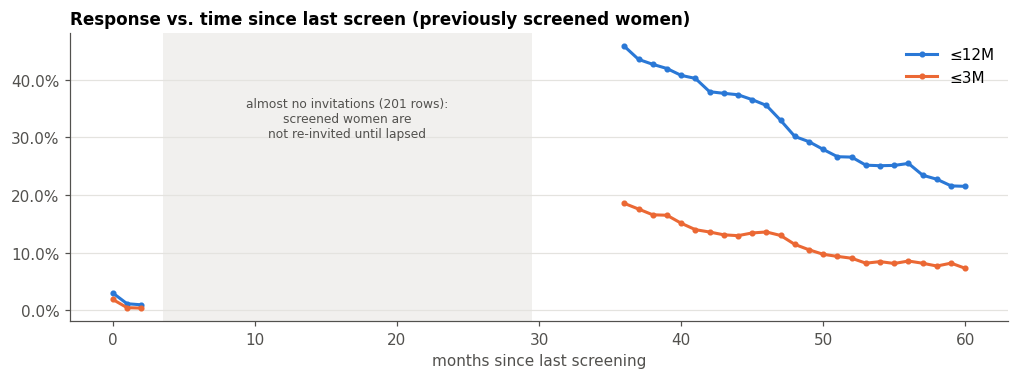

MONTHS_SINCE_LAST_SCREEN,"(-1, 3]","(3, 29]","(29, 36]","(36, 48]","(48, 60]","(60, 80]"
rows,36289,201,12865,120784,73938,193


In [22]:
fig, ax = plt.subplots(figsize=(11, 3.4))
t = df[df.MONTHS_SINCE_LAST_SCREEN.notna()].groupby("MONTHS_SINCE_LAST_SCREEN").agg(
    r12=("SCREENING_12M_FLAG", "mean"), r3=("SCREENING_3M_FLAG", "mean"), n=("SCREENING_12M_FLAG", "size"))
t = t[t.n >= 200].reindex(range(0, 61))  # NaN months break the line instead of interpolating across the gap
ax.plot(t.index, t.r12, color=C1, marker="o", ms=3, label="≤12M"); ax.plot(t.index, t.r3, color=C2, marker="o", ms=3, label="≤3M")
ax.axvspan(3.5, 29.5, color=GRID, alpha=0.5, lw=0)
ax.text(16.5, 0.3, "almost no invitations (201 rows):\nscreened women are\nnot re-invited until lapsed", ha="center", color=INK2, fontsize=8)
ax.yaxis.set_major_formatter(pct); ax.set_xlabel("months since last screening")
ax.set_title("Response vs. time since last screen (previously screened women)"); ax.legend()
plt.show()
pd.cut(df.MONTHS_SINCE_LAST_SCREEN, [-1, 3, 29, 36, 48, 60, 80]).value_counts(sort=False).to_frame("rows").T

### 6.4 Preventive behaviour and healthcare contact

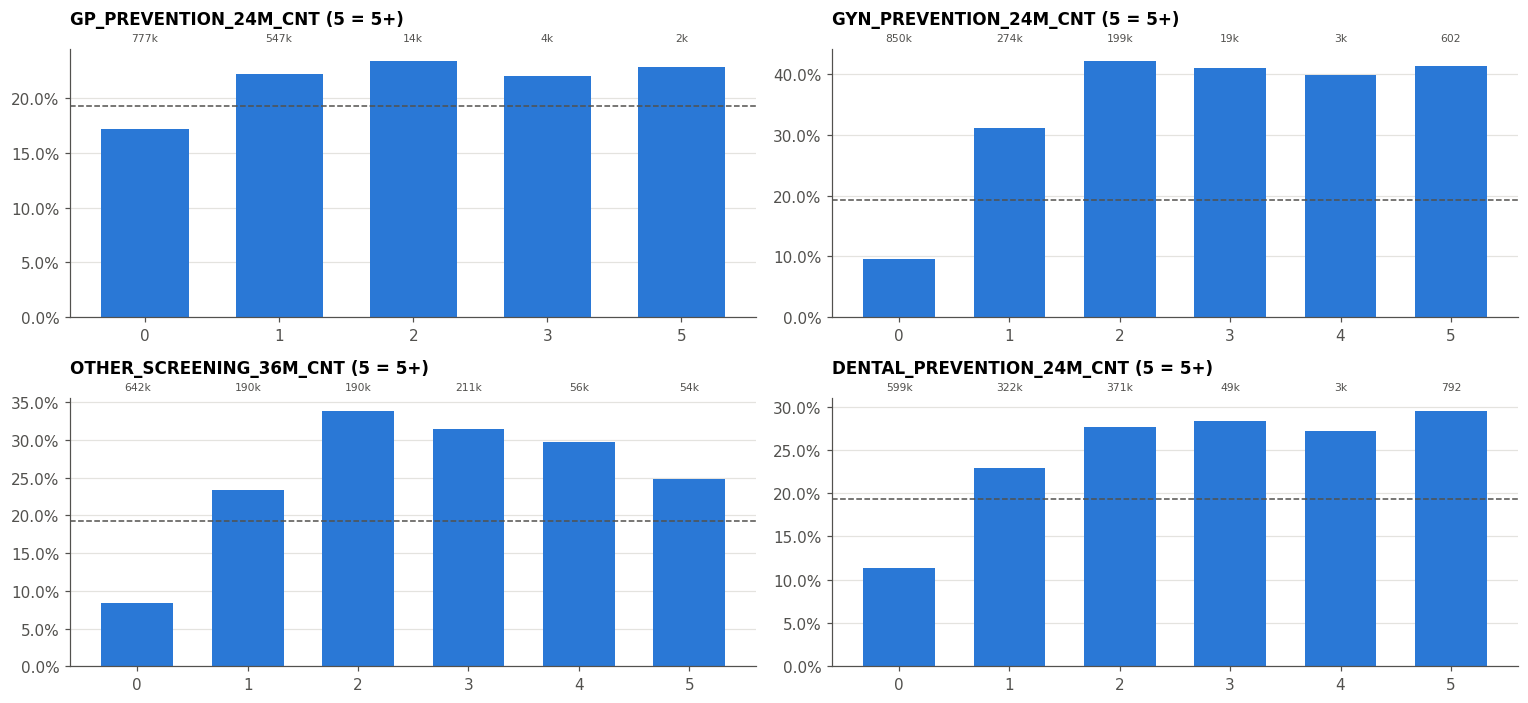

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6.5))
for ax, c in zip(axes.flat, ["GP_PREVENTION_24M_CNT", "GYN_PREVENTION_24M_CNT", "OTHER_SCREENING_36M_CNT", "DENTAL_PREVENTION_24M_CNT"]):
    d = df.assign(**{c: df[c].clip(upper=5)})
    rate_plot(c, data=d, ax=ax, title=f"{c} (5 = 5+)")
plt.tight_layout(); plt.show()

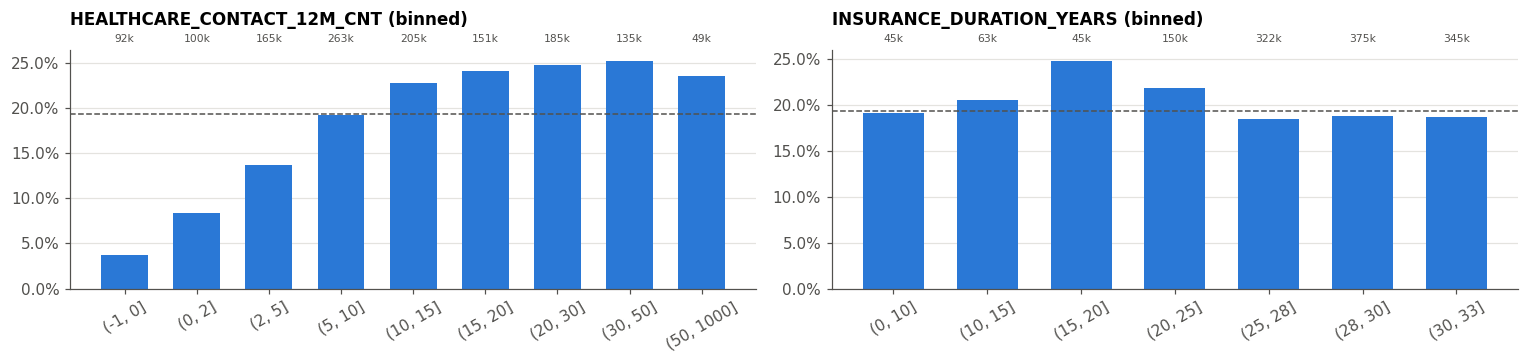

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
hc_bins = [-1, 0, 2, 5, 10, 15, 20, 30, 50, 1000]
d = df.assign(HC=pd.cut(df.HEALTHCARE_CONTACT_12M_CNT, hc_bins))
rate_plot("HC", data=d, ax=axes[0], title="HEALTHCARE_CONTACT_12M_CNT (binned)", rot=30)
d = df.assign(INS=pd.cut(df.INSURANCE_DURATION_YEARS, [0, 10, 15, 20, 25, 28, 30, 33]))
rate_plot("INS", data=d, ax=axes[1], title="INSURANCE_DURATION_YEARS (binned)", rot=30)
plt.tight_layout(); plt.show()

### 6.5 Doctor registration

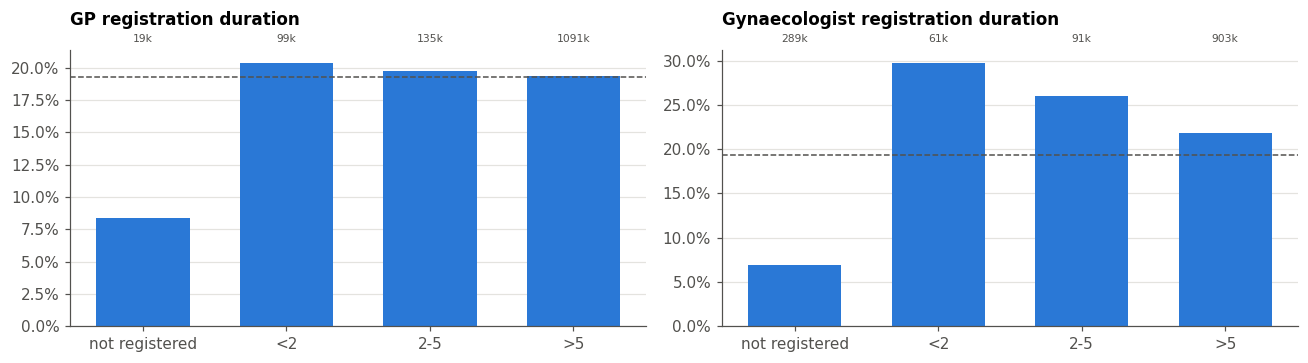

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
d = df.assign(GP=df.GP_REG_DURATION_BAND.astype(str).replace("nan", "not registered"))
rate_plot("GP", data=d, ax=axes[0], order=["not registered", "<2", "2-5", ">5"], title="GP registration duration")
d = df.assign(GYN=df.GYN_REG_DURATION_BAND.astype(str).replace("nan", "not registered"))
rate_plot("GYN", data=d, ax=axes[1], order=["not registered", "<2", "2-5", ">5"], title="Gynaecologist registration duration")
plt.tight_layout(); plt.show()

## 7. Feature correlations

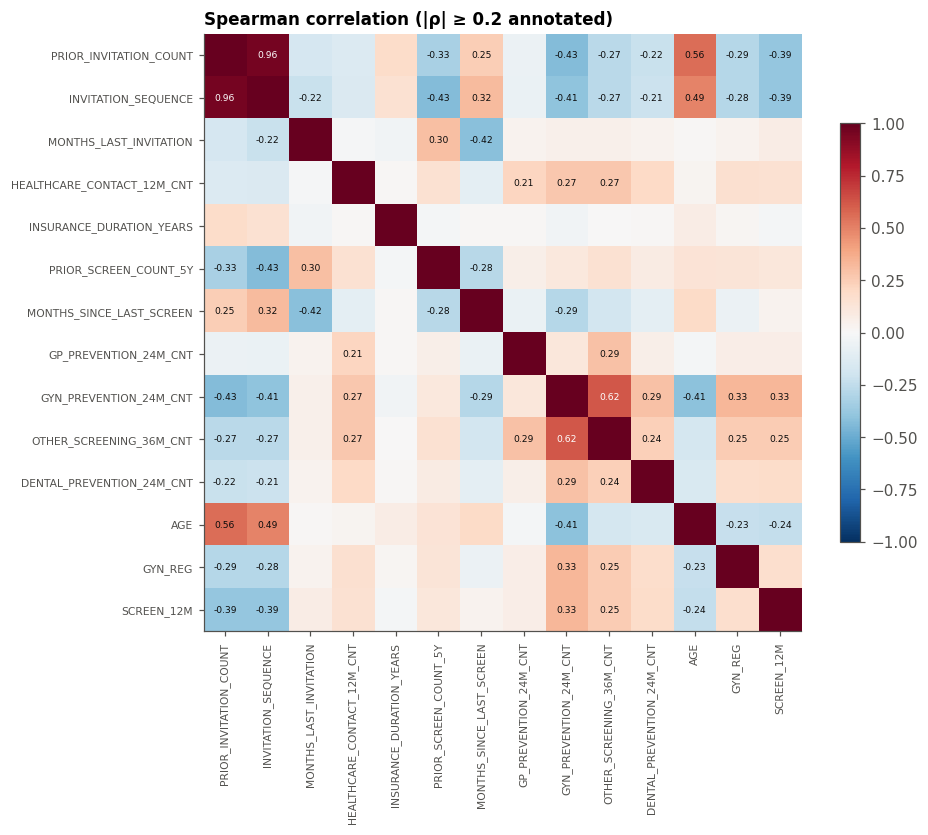

,ρ with 12M label
PRIOR_INVITATION_COUNT,-0.390237
INVITATION_SEQUENCE,-0.386297
GYN_PREVENTION_24M_CNT,0.332179
OTHER_SCREENING_36M_CNT,0.253989
AGE,-0.240734
DENTAL_PREVENTION_24M_CNT,0.182591
GYN_REG,0.164285
HEALTHCARE_CONTACT_12M_CNT,0.149514
PRIOR_SCREEN_COUNT_5Y,0.116954
MONTHS_LAST_INVITATION,0.077328


In [26]:
NUM = ["PRIOR_INVITATION_COUNT", "INVITATION_SEQUENCE", "MONTHS_LAST_INVITATION", "HEALTHCARE_CONTACT_12M_CNT",
       "INSURANCE_DURATION_YEARS", "PRIOR_SCREEN_COUNT_5Y", "MONTHS_SINCE_LAST_SCREEN", "GP_PREVENTION_24M_CNT",
       "GYN_PREVENTION_24M_CNT", "OTHER_SCREENING_36M_CNT", "DENTAL_PREVENTION_24M_CNT"]
age_mid = df.AGE_BAND.astype(str).str[:2].astype(int) + 2
corr = df[NUM].assign(AGE=age_mid, GYN_REG=df.GYN_REGISTERED_FLAG.astype(int),
                      SCREEN_12M=df.SCREENING_12M_FLAG.astype(int)).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        if abs(v) >= 0.2 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, shrink=0.7); ax.set_title("Spearman correlation (|ρ| ≥ 0.2 annotated)")
plt.tight_layout(); plt.show()
corr["SCREEN_12M"].drop("SCREEN_12M").sort_values(key=abs, ascending=False).to_frame("ρ with 12M label")

## 8. Key findings

**Data quality**
- 1,344,556 invitations for 508,527 women. There are no duplicates, and every NaN is *structural*: each one is fully explained by a flag (`FIRST_INVITATION`, `NEVER_SCREENED_BEFORE_FLAG`, `GP_REGISTERED`, `GYN_REGISTERED_FLAG`). Impute with a sentinel or a "missing" category, not with a mean.
- Small inconsistencies:
  - 3,354 rows have `NEVER_SCREENED = N` but `PRIOR_SCREEN_COUNT_5Y = 0`. This is a 60-month window-edge effect.
  - 193 rows have `MONTHS_SINCE_LAST_SCREEN > 60`, although the documented window is 60 months.
  - 52 rows have `FIRST_INVITATION = A` but `INVITATION_SEQUENCE = 2`.
- `PRIOR_SCREEN_COUNT_5Y` is mostly **2** (196k rows) rather than 1 (8k). It probably counts claim codes, not visits (2 codes per mammography visit?). Worth asking the organisers.

**Targets**
- 3M / 6M / 12M positive rates are 7.1% / 12.5% / 19.3%. The labels are strictly nested, and about 35% of 12-month responders come after month 6.
- Rates are stable at about 19–20% for 2021–2024. 2020 is lower (17.8%) and has COVID gaps in invitation sending (spring and autumn 2020).

**Population structure (important for modelling)**
- **Invitations target non-attenders.** Previously screened women are only invited once they have lapsed (≥30 months since the last screen). A separate cluster of about 36k rows was screened 0–3 months before T0, and these rarely respond (~2%).
- Repeat invitations come about every 12 months. **Response falls sharply with `INVITATION_SEQUENCE`**, from 46% on the 1st invitation to about 3% on the 11th: chronic non-attenders get re-invited again and again.
- **The 40–44 band (100% first invitations) responds at 57%**, and 45–49 at 31%. These are first-time invitees, a very different group from the 50+ re-invited population. Consider a separate model or interaction terms.
- 86% of rows belong to women with more than one invitation, and consecutive invitations are about 12 months apart, so **12M label windows overlap with the next invitation**. Use out-of-time splits with a gap (or at least splits grouped by `PERSON_ID`).

**Predictors**
- The strongest signals are invitation history (`PRIOR_INVITATION_COUNT`, `INVITATION_SEQUENCE`), `MONTHS_SINCE_LAST_SCREEN`, and preventive behaviour: `GYN_PREVENTION_24M_CNT` (10% response at 0 visits vs. 42% at 2+), `OTHER_SCREENING_36M_CNT`, `HEALTHCARE_CONTACT_12M_CNT` (4% response with zero contacts).
- Not being registered with a gynaecologist (7%) or a GP (9%) strongly predicts non-response.
- Regional spread across the 75 VZP areas is 12.8%–23.8%: modest but real.
- Insurance duration and GP prevention counts are weak.

**Baseline**
- An untuned HistGradientBoosting model (see [`baseline/`](../baseline/train.py)), trained on 2020–2021 and tested on 2023–2024, reaches **ROC AUC ≈ 0.83** for all three horizons. PR AUC is 0.28 / 0.43 / 0.58 against base rates of 0.07 / 0.13 / 0.20.

**Next steps**
- Sequence features built from earlier rows of the same woman: previous response, number of past non-responses.
- Handle the 40–44 cohort and first invitations explicitly.
- Calibrate predictions and evaluate them per invitation batch.
- Clarify the claim-code semantics of `PRIOR_SCREEN_COUNT_5Y` with the organisers.